## Experiment using the K-Medoids

In [1]:
%load_ext autoreload
%autoreload 2


from index.inverted_index import Index
from index.documents import load_dataset, tokenizer

msmarco = load_dataset("msmarco-passage/dev/judged")

NUM_DOCS = 100000
# K = 10

## Create the inverting index using shuffle

In [ ]:
import random
from index.ordered_dataset import OrderedDataset

docs = []
for i, doc in enumerate(msmarco.docs_iter()):
    docs.append(doc)
    if i == NUM_DOCS - 1:
        break

order = list(range(1, NUM_DOCS + 1))
random.shuffle(order)

random_dataset = OrderedDataset(docs, order)


unordered_index = Index()
unordered_index.build_index(random_dataset, tokenizer, max_num_docs=NUM_DOCS)

Processing:   99.0% [99000/100000] | Current docid: 99000               

## Creating the tf-idf matrix

In [3]:
from index.reorder_utils import create_sparse_tf_idf_matrix
import pandas as pd

tf_idf_matrix, doc_ids, terms = create_sparse_tf_idf_matrix(unordered_index)
df = pd.DataFrame.sparse.from_spmatrix(tf_idf_matrix, index=doc_ids, columns=terms)


In [4]:
import warnings
from sklearn.exceptions import DataConversionWarning

warnings.filterwarnings("ignore", category=DataConversionWarning)

In [5]:
from time import perf_counter
import copy

def prepare_index(src_index, method):
    idx = copy.deepcopy(src_index)

    if(method == "none"):
        return idx.get_approx_size(), 0

    
    if not src_index.removed_tf : 
        idx.remove_tf()

    start = perf_counter()

    idx.compress_index(method)

    elapsed_time = perf_counter() - start
    
    return idx.get_approx_size(), elapsed_time


In [6]:
from index.reorder_utils import k_medoids, reorder_documents_by_tsp, tsp_path, calculate_distance_matrix
def TSP_order(df,k):

    print(f"using {k} total clusters")
    medoids, medoids_id, cluster_to_docs = k_medoids(df, k)
    
    dist_matrix = calculate_distance_matrix(medoids, method="jaccard")
    tsp_path_ = tsp_path(dist_matrix)
    new_order = reorder_documents_by_tsp(tsp_path_,cluster_to_docs, medoids_id)
    ordered_dataset = OrderedDataset(docs, new_order)

    return ordered_dataset


## Experiment varying the k

In [7]:
import copy


"""
For each k we store the stats for each compression type.
"""

K = range(10,1000, 100)

time_unordered_gamma = []
time_ordered_gamma = []
results_unordered_gamma = []
results_ordered_gamma = []

time_unordered_delta = []
time_ordered_delta = []
results_unordered_delta = []
results_ordered_delta = []

time_unordered_var_byte = []
time_ordered_var_byte = []
results_unordered_var_byte = []
results_ordered_var_byte = []

time_unordered_pfor_delta = []
time_ordered_pfor_delta = []
results_unordered_pfor_delta = []
results_ordered_pfor_delta = []

time_unordered_uncompressed = []
time_ordered_uncompressed = []
results_unordered_uncompressed = []
results_ordered_uncompressed = []


unordered_index = Index()
unordered_index.clear_index()
unordered_index.build_index(random_dataset,tokenizer,max_num_docs=NUM_DOCS,d_gap=True)

for k in K:

    reordered_index = Index()
    reordered_index.clear_index()
    reordered_index.build_index(TSP_order(df,k),tokenizer,max_num_docs=NUM_DOCS,d_gap=True)

    # compression stat for unordered index
    
    gamma_index_stat_unordered, gamma_time_unordered = prepare_index(unordered_index, "gamma")
    delta_index_stat_unordered, delta_time_unordered = prepare_index(unordered_index, "delta")
    vb_index_stat_unordered , vb_time_unordered= prepare_index(unordered_index, "varbyte")
    pfor_index_stat_unordered, pfor_time_unordered = prepare_index(unordered_index, "pfor_delta")
    uncompressed_stat_unordered, uncompressed_time_unordered = prepare_index(unordered_index, "none")

    results_unordered_gamma.append(gamma_index_stat_unordered)
    time_unordered_gamma.append(gamma_time_unordered)

    results_unordered_delta.append(delta_index_stat_unordered)
    time_unordered_delta.append(delta_time_unordered)

    results_unordered_var_byte.append(vb_index_stat_unordered)
    time_unordered_var_byte.append(vb_time_unordered)

    results_unordered_pfor_delta.append(pfor_index_stat_unordered)
    time_unordered_pfor_delta.append(pfor_time_unordered)
    
    results_unordered_uncompressed.append(uncompressed_stat_unordered)
    time_unordered_uncompressed.append(uncompressed_time_unordered)

    # compression stat for ordered index

    gamma_index_stat_ordered, gamma_time_ordered = prepare_index(reordered_index, "gamma")
    delta_index_stat_ordered, delta_time_ordered = prepare_index(reordered_index, "delta")
    vb_index_stat_ordered , vb_time_ordered= prepare_index(reordered_index, "varbyte")
    pfor_index_stat_ordered, pfor_time_ordered = prepare_index(reordered_index, "pfor_delta")
    uncompressed_stat_ordered, uncompressed_time_ordered = prepare_index(unordered_index, "none")

    results_ordered_gamma.append(gamma_index_stat_ordered)
    time_ordered_gamma.append(gamma_time_ordered)

    results_ordered_delta.append(delta_index_stat_ordered)
    time_ordered_delta.append(delta_time_ordered)

    results_ordered_var_byte.append(vb_index_stat_ordered)
    time_ordered_var_byte.append(vb_time_ordered)

    results_ordered_pfor_delta.append(pfor_index_stat_ordered)
    time_ordered_pfor_delta.append(pfor_time_ordered)

    results_ordered_uncompressed.append(uncompressed_stat_ordered)
    time_ordered_uncompressed.append(uncompressed_time_ordered)



Processing:   99.0% [99000/100000] | Current docid: 99000               using 10 total clusters


c:\Users\Utente\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Impossibile trovare il file specificato
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Utente\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "c:\Users\Utente\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
  File "c:\Users\Utente\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\Ut

Processing:   99.0% [99000/100000] | Current docid: 99000               Handling PForDelta with is_decompressing=False
Handling PForDelta with is_decompressing=False
using 110 total clusters
Processing:   99.0% [99000/100000] | Current docid: 99000               Handling PForDelta with is_decompressing=False
Handling PForDelta with is_decompressing=False
using 210 total clusters
Processing:   99.0% [99000/100000] | Current docid: 99000               Handling PForDelta with is_decompressing=False
Handling PForDelta with is_decompressing=False
using 310 total clusters
Processing:   99.0% [99000/100000] | Current docid: 99000               Handling PForDelta with is_decompressing=False
Handling PForDelta with is_decompressing=False
using 410 total clusters
Processing:   99.0% [99000/100000] | Current docid: 99000               Handling PForDelta with is_decompressing=False
Handling PForDelta with is_decompressing=False
using 510 total clusters
Processing:   99.0% [99000/100000] | Current 

In [8]:
import pandas as pd

# save the results in a CSV file for later analysis
data_to_save = {
    "K": list(K),
    
    
    "Unordered_Gamma_Bytes": results_unordered_gamma,
    "Unordered_Gamma_Time": time_unordered_gamma,
    "Unordered_Delta_Bytes": results_unordered_delta,
    "Unordered_Delta_Time": time_unordered_delta,
    "Unordered_VarByte_Bytes": results_unordered_var_byte,
    "Unordered_VarByte_Time": time_unordered_var_byte,
    "Unordered_PForDelta_Bytes": results_unordered_pfor_delta,
    "Unordered_PForDelta_Time": time_unordered_pfor_delta,
    "Unordered_Uncompressed_Bytes": results_unordered_uncompressed,
    "Unordered_Uncompressed_Time": time_unordered_uncompressed,
    
    
    "Ordered_Gamma_Bytes": results_ordered_gamma,
    "Ordered_Gamma_Time": time_ordered_gamma,
    "Ordered_Delta_Bytes": results_ordered_delta,
    "Ordered_Delta_Time": time_ordered_delta,
    "Ordered_VarByte_Bytes": results_ordered_var_byte,
    "Ordered_VarByte_Time": time_ordered_var_byte,
    "Ordered_PForDelta_Bytes": results_ordered_pfor_delta,
    "Ordered_PForDelta_Time": time_ordered_pfor_delta,
    "Ordered_Uncompressed_Bytes": results_ordered_uncompressed,
    "Ordered_Uncompressed_Time": time_ordered_uncompressed
}

df_risultati = pd.DataFrame(data_to_save)

df_risultati.to_csv("compression_results_kMedoids.csv", index=False)

Unordered Gamma (MB): [5.547109127044678, 5.547109127044678, 5.547109127044678, 5.547109127044678, 5.547109127044678, 5.547109127044678, 5.547109127044678, 5.547109127044678, 5.547109127044678]


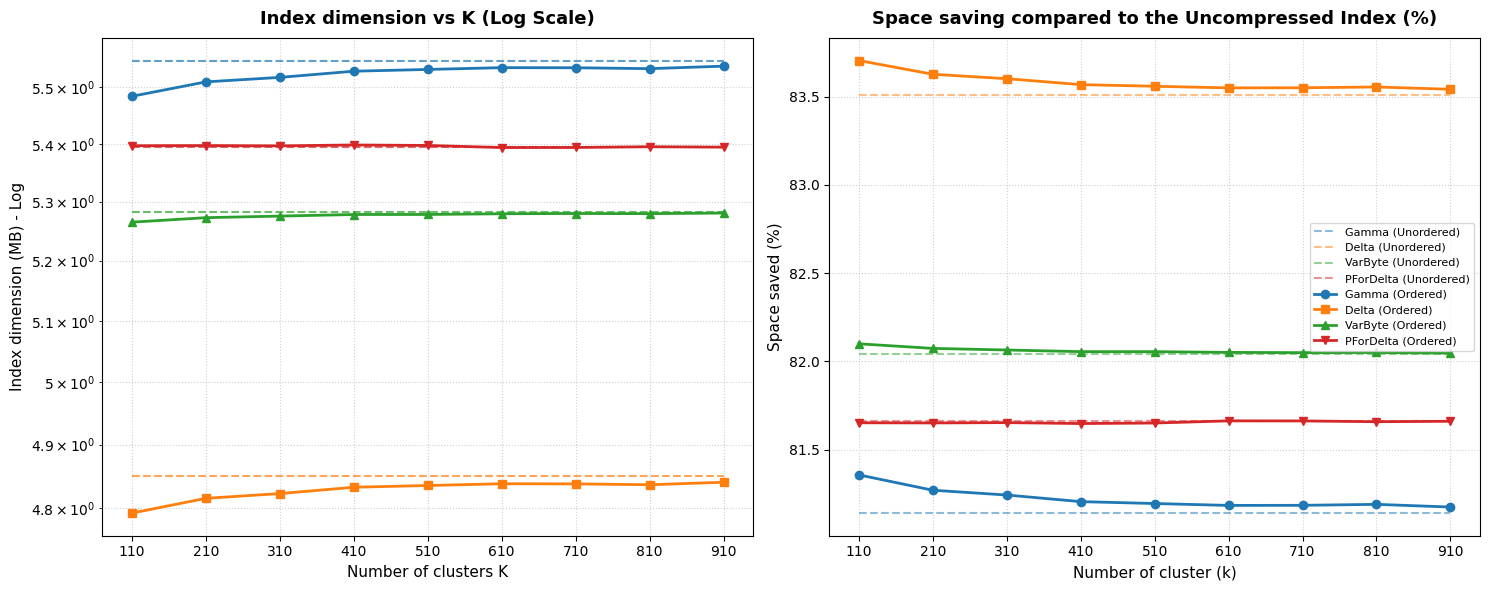

In [ ]:
import ast
import matplotlib.pyplot as plt
import pandas as pd


def extract_bytes(series):
   
    return series.apply(lambda x: ast.literal_eval(x)["total_bytes"])

df = pd.read_csv("compression_results_kMedoids_no_ten.csv")


K = df["K"].tolist()

MB_FACTOR = 1024**2


# Unordered
un_gamma = (extract_bytes(df["Unordered_Gamma_Bytes"]) / MB_FACTOR).tolist()
un_delta = (extract_bytes(df["Unordered_Delta_Bytes"]) / MB_FACTOR).tolist()
un_varbyte = (extract_bytes(df["Unordered_VarByte_Bytes"]) / MB_FACTOR).tolist()
un_pfor = (extract_bytes(df["Unordered_PForDelta_Bytes"]) / MB_FACTOR).tolist()
un_uncompressed = (
    extract_bytes(df["Unordered_Uncompressed_Bytes"]) / MB_FACTOR
).tolist()

print("Unordered Gamma (MB):", un_gamma)

# Ordered
or_gamma = (extract_bytes(df["Ordered_Gamma_Bytes"]) / MB_FACTOR).tolist()
or_delta = (extract_bytes(df["Ordered_Delta_Bytes"]) / MB_FACTOR).tolist()
or_varbyte = (extract_bytes(df["Ordered_VarByte_Bytes"]) / MB_FACTOR).tolist()
or_pfor = (extract_bytes(df["Ordered_PForDelta_Bytes"]) / MB_FACTOR).tolist()
or_uncompressed = (
    extract_bytes(df["Ordered_Uncompressed_Bytes"]) / MB_FACTOR
).tolist()



fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

colors = {
    "Gamma": "#1f77b4",
    "Delta": "#ff7f0e",
    "VarByte": "#2ca02c",
    "PForDelta": "#d62728",
    "Uncompressed": "#7f7f7f",
}

ax1.plot(
    K,
    un_gamma,
    linestyle="--",
    color=colors["Gamma"],
    alpha=0.7,
    label="Gamma (Unordered)",
)
ax1.plot(
    K,
    un_delta,
    linestyle="--",
    color=colors["Delta"],
    alpha=0.7,
    label="Delta (Unordered)",
)
ax1.plot(
    K,
    un_varbyte,
    linestyle="--",
    color=colors["VarByte"],
    alpha=0.7,
    label="VarByte (Unordered)",
)
ax1.plot(
    K,
    un_pfor,
    linestyle="--",
    color=colors["PForDelta"],
    alpha=0.7,
    label="PForDelta (Unordered, no TF)",
)
# ax1.plot(
#     K,
#     un_uncompressed,
#     linestyle="--",
#     color=colors["Uncompressed"],
#     alpha=0.7,
#     label="Uncompressed Baseline",
# )

ax1.plot(
    K,
    or_gamma,
    marker="o",
    linestyle="-",
    color=colors["Gamma"],
    linewidth=2,
    label="Gamma (Ordered)",
)
ax1.plot(
    K,
    or_delta,
    marker="s",
    linestyle="-",
    color=colors["Delta"],
    linewidth=2,
    label="Delta (Ordered)",
)
ax1.plot(
    K,
    or_varbyte,
    marker="^",
    linestyle="-",
    color=colors["VarByte"],
    linewidth=2,
    label="VarByte (Ordered)",
)
ax1.plot(
    K,
    or_pfor,
    marker="v",
    linestyle="-",
    color=colors["PForDelta"],
    linewidth=2,
    label="PForDelta (Ordered, no TF)",
)

ax1.set_yscale("log")
ax1.set_title(
    "Index dimension vs K (Log Scale)", fontsize=13, fontweight="bold", pad=10
)
ax1.set_xlabel("Number of clusters K", fontsize=11)
ax1.set_ylabel("Index dimension (MB) - Log", fontsize=11)
ax1.set_xticks(K)
ax1.grid(True, which="both", linestyle=":", alpha=0.6)


def get_savings_vs_uncompressed(compressed_list, uncompressed_list):
    return [
        (uncomp - comp) / uncomp * 100
        for comp, uncomp in zip(compressed_list, uncompressed_list)
    ]


ax2.plot(
    K,
    get_savings_vs_uncompressed(un_gamma, un_uncompressed),
    linestyle="--",
    color=colors["Gamma"],
    alpha=0.5,
    label="Gamma (Unordered)",
)
ax2.plot(
    K,
    get_savings_vs_uncompressed(un_delta, un_uncompressed),
    linestyle="--",
    color=colors["Delta"],
    alpha=0.5,
    label="Delta (Unordered)",
)
ax2.plot(
    K,
    get_savings_vs_uncompressed(un_varbyte, un_uncompressed),
    linestyle="--",
    color=colors["VarByte"],
    alpha=0.5,
    label="VarByte (Unordered)",
)
ax2.plot(
    K,
    get_savings_vs_uncompressed(un_pfor, un_uncompressed),
    linestyle="--",
    color=colors["PForDelta"],
    alpha=0.5,
    label="PForDelta (Unordered)",
)

ax2.plot(
    K,
    get_savings_vs_uncompressed(or_gamma, un_uncompressed),
    marker="o",
    linestyle="-",
    color=colors["Gamma"],
    linewidth=2,
    label="Gamma (Ordered)",
)
ax2.plot(
    K,
    get_savings_vs_uncompressed(or_delta, un_uncompressed),
    marker="s",
    linestyle="-",
    color=colors["Delta"],
    linewidth=2,
    label="Delta (Ordered)",
)
ax2.plot(
    K,
    get_savings_vs_uncompressed(or_varbyte, un_uncompressed),
    marker="^",
    linestyle="-",
    color=colors["VarByte"],
    linewidth=2,
    label="VarByte (Ordered)",
)
ax2.plot(
    K,
    get_savings_vs_uncompressed(or_pfor, un_uncompressed),
    marker="v",
    linestyle="-",
    color=colors["PForDelta"],
    linewidth=2,
    label="PForDelta (Ordered)",
)

ax2.set_title(
    "Space saving compared to the Uncompressed Index (%)",
    fontsize=13,
    fontweight="bold",
    pad=10,
)
ax2.set_xlabel("Number of cluster (k)", fontsize=11)
ax2.set_ylabel("Space saved (%)", fontsize=11)
ax2.set_xticks(K)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(fontsize=8, loc="best", frameon=True)

plt.tight_layout()
plt.show()

[5.547109127044678, 5.547109127044678, 5.547109127044678, 5.547109127044678, 5.547109127044678, 5.547109127044678, 5.547109127044678, 5.547109127044678, 5.547109127044678, 5.547109127044678]


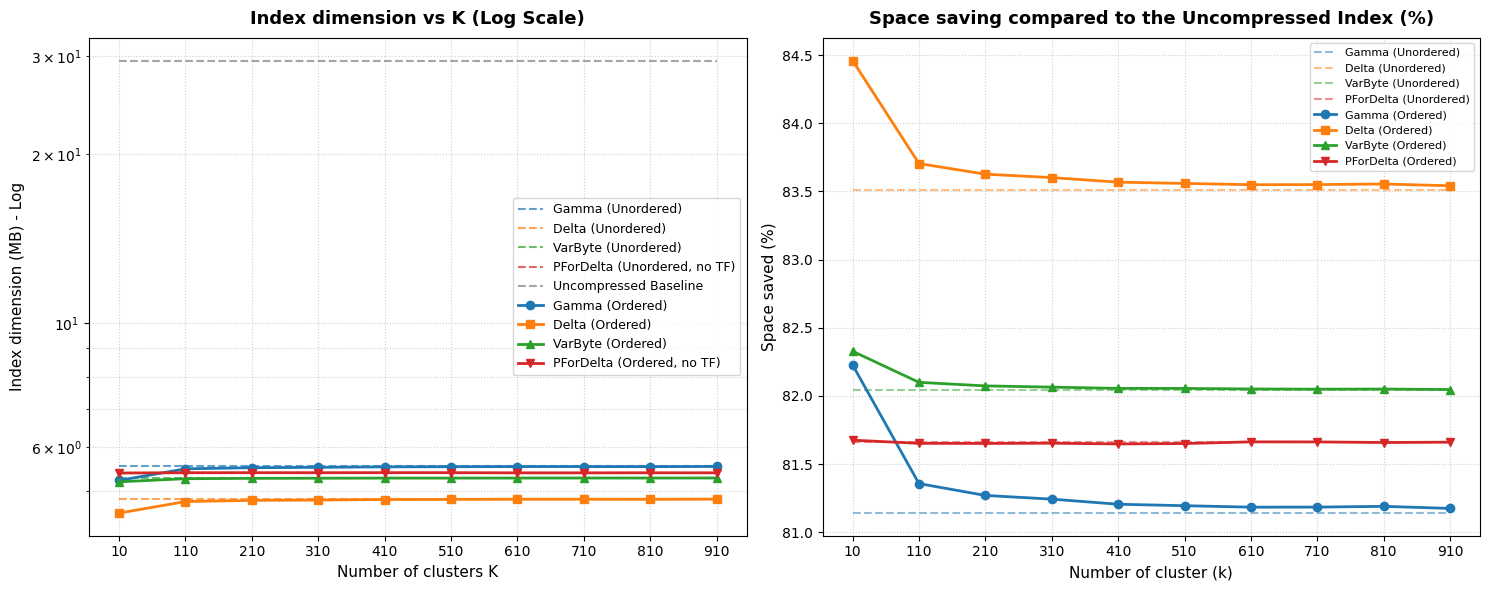

In [ ]:
import matplotlib.pyplot as plt

MB_FACTOR = 1024 ** 2


# Unordered
un_gamma = [res["total_bytes"] / MB_FACTOR for res in results_unordered_gamma]
un_delta = [res["total_bytes"] / MB_FACTOR for res in results_unordered_delta]
un_varbyte = [res["total_bytes"] / MB_FACTOR for res in results_unordered_var_byte]
un_pfor = [res["total_bytes"] / MB_FACTOR for res in results_unordered_pfor_delta]
un_uncompressed = [res["total_bytes"] / MB_FACTOR for res in results_unordered_uncompressed]

print(un_gamma)


# Ordered
or_gamma = [res["total_bytes"] / MB_FACTOR for res in results_ordered_gamma]
or_delta = [res["total_bytes"] / MB_FACTOR for res in results_ordered_delta]
or_varbyte = [res["total_bytes"] / MB_FACTOR for res in results_ordered_var_byte]
or_pfor = [res["total_bytes"] / MB_FACTOR for res in results_ordered_pfor_delta]
or_uncompressed = [res["total_bytes"] / MB_FACTOR for res in results_ordered_uncompressed]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

colors = {
    'Gamma': '#1f77b4', 
    'Delta': '#ff7f0e', 
    'VarByte': '#2ca02c', 
    'PForDelta': '#d62728',
    'Uncompressed': '#7f7f7f'  
}


ax1.plot(K, un_gamma, linestyle='--', color=colors['Gamma'], alpha=0.7, label='Gamma (Unordered)')
ax1.plot(K, un_delta, linestyle='--', color=colors['Delta'], alpha=0.7, label='Delta (Unordered)')
ax1.plot(K, un_varbyte, linestyle='--', color=colors['VarByte'], alpha=0.7, label='VarByte (Unordered)')
ax1.plot(K, un_pfor, linestyle='--', color=colors['PForDelta'], alpha=0.7, label='PForDelta (Unordered, no TF)')
ax1.plot(K, un_uncompressed, linestyle='--', color=colors['Uncompressed'], alpha=0.7, label='Uncompressed Baseline')

ax1.plot(K, or_gamma, marker='o', linestyle='-', color=colors['Gamma'], linewidth=2, label='Gamma (Ordered)')
ax1.plot(K, or_delta, marker='s', linestyle='-', color=colors['Delta'], linewidth=2, label='Delta (Ordered)')
ax1.plot(K, or_varbyte, marker='^', linestyle='-', color=colors['VarByte'], linewidth=2, label='VarByte (Ordered)')
ax1.plot(K, or_pfor, marker='v', linestyle='-', color=colors['PForDelta'], linewidth=2, label='PForDelta (Ordered, no TF)')


ax1.set_yscale('log')

ax1.set_title("Index dimension vs K (Log Scale)", fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel("Number of clusters K", fontsize=11)
ax1.set_ylabel("Index dimension (MB) - Log", fontsize=11)
ax1.set_xticks(K)

ax1.grid(True, which="both", linestyle=':', alpha=0.6)

ax1.legend(fontsize=9, loc='best', frameon=True)



def get_savings_vs_uncompressed(compressed_list, uncompressed_list):
    return [(uncomp - comp) / uncomp * 100 for comp, uncomp in zip(compressed_list, uncompressed_list)]


ax2.plot(K, get_savings_vs_uncompressed(un_gamma, un_uncompressed), linestyle='--', color=colors['Gamma'], alpha=0.5, label='Gamma (Unordered)')
ax2.plot(K, get_savings_vs_uncompressed(un_delta, un_uncompressed), linestyle='--', color=colors['Delta'], alpha=0.5, label='Delta (Unordered)')
ax2.plot(K, get_savings_vs_uncompressed(un_varbyte, un_uncompressed), linestyle='--', color=colors['VarByte'], alpha=0.5, label='VarByte (Unordered)')
ax2.plot(K, get_savings_vs_uncompressed(un_pfor, un_uncompressed), linestyle='--', color=colors['PForDelta'], alpha=0.5, label='PForDelta (Unordered)')


ax2.plot(K, get_savings_vs_uncompressed(or_gamma, un_uncompressed), marker='o', linestyle='-', color=colors['Gamma'], linewidth=2, label='Gamma (Ordered)')
ax2.plot(K, get_savings_vs_uncompressed(or_delta, un_uncompressed), marker='s', linestyle='-', color=colors['Delta'], linewidth=2, label='Delta (Ordered)')
ax2.plot(K, get_savings_vs_uncompressed(or_varbyte, un_uncompressed), marker='^', linestyle='-', color=colors['VarByte'], linewidth=2, label='VarByte (Ordered)')
ax2.plot(K, get_savings_vs_uncompressed(or_pfor, un_uncompressed), marker='v', linestyle='-', color=colors['PForDelta'], linewidth=2, label='PForDelta (Ordered)')

ax2.set_title("Space saving compared to the Uncompressed Index (%)", fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel("Number of cluster (k)", fontsize=11)
ax2.set_ylabel("Space saved (%)", fontsize=11)
ax2.set_xticks(K)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(fontsize=8, loc='best', frameon=True)


plt.tight_layout()
plt.show() 

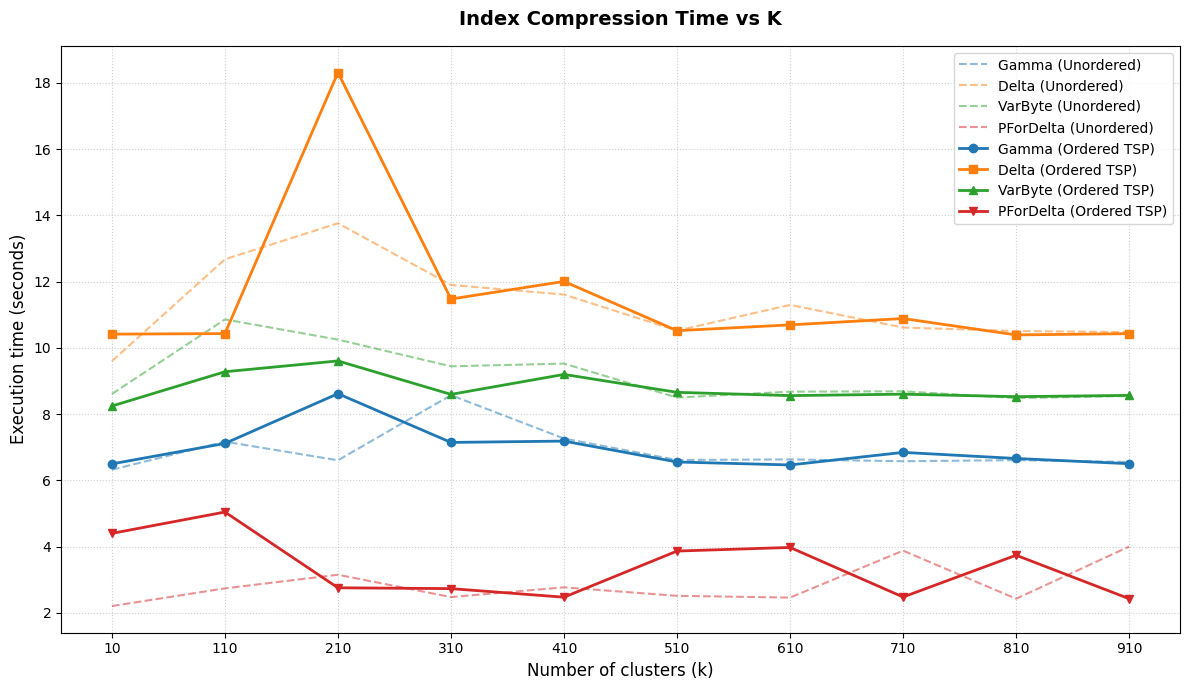

In [ ]:
import matplotlib.pyplot as plt


N = len(K)

t_un_gamma = time_unordered_gamma[-N:]
t_un_delta = time_unordered_delta[-N:]
t_un_varbyte = time_unordered_var_byte[-N:]
t_un_pfor = time_unordered_pfor_delta[-N:]


t_or_gamma = time_ordered_gamma[-N:]
t_or_delta = time_ordered_delta[-N:]
t_or_varbyte = time_ordered_var_byte[-N:]
t_or_pfor = time_ordered_pfor_delta[-N:]

plt.figure(figsize=(12, 7))

i
colors = {
    'Gamma': '#1f77b4', 
    'Delta': '#ff7f0e', 
    'VarByte': '#2ca02c', 
    'PForDelta': '#d62728'
}


plt.plot(K, t_un_gamma, linestyle='--', color=colors['Gamma'], alpha=0.5, label='Gamma (Unordered)')
plt.plot(K, t_un_delta, linestyle='--', color=colors['Delta'], alpha=0.5, label='Delta (Unordered)')
plt.plot(K, t_un_varbyte, linestyle='--', color=colors['VarByte'], alpha=0.5, label='VarByte (Unordered)')
plt.plot(K, t_un_pfor, linestyle='--', color=colors['PForDelta'], alpha=0.5, label='PForDelta (Unordered)')

plt.plot(K, t_or_gamma, marker='o', linestyle='-', color=colors['Gamma'], linewidth=2, label='Gamma (Ordered TSP)')
plt.plot(K, t_or_delta, marker='s', linestyle='-', color=colors['Delta'], linewidth=2, label='Delta (Ordered TSP)')
plt.plot(K, t_or_varbyte, marker='^', linestyle='-', color=colors['VarByte'], linewidth=2, label='VarByte (Ordered TSP)')
plt.plot(K, t_or_pfor, marker='v', linestyle='-', color=colors['PForDelta'], linewidth=2, label='PForDelta (Ordered TSP)')

plt.title("Index Compression Time vs K", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Number of clusters (k)", fontsize=12)
plt.ylabel("Execution time (seconds)", fontsize=12)
plt.xticks(K)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10, loc='best', frameon=True)

plt.tight_layout()
plt.show()

## D-Gap vs no D-Gap

In [12]:
import copy
from index.reorder_utils import k_medoids, reorder_documents_by_tsp, tsp_path, calculate_distance_matrix


k = 50

time_no_d_gap_gamma = []
time_d_gap_gamma = []
results_no_d_gap_gamma = []
results_d_gap_gamma = []

time_no_d_gap_delta = []
time_d_gap_delta = []
results_no_d_gap_delta = []
results_d_gap_delta = []

time_no_d_gap_var_byte = []
time_d_gap_var_byte = []
results_no_d_gap_var_byte = []
results_d_gap_var_byte = []

time_no_d_gap_pfor_delta = []
time_d_gap_pfor_delta = []
results_no_d_gap_pfor_delta = []
results_d_gap_pfor_delta = []


ordered_dataset = TSP_order(df,k)


# no d-gap index
no_d_gap_index = Index()
no_d_gap_index.clear_index()
no_d_gap_index.build_index(ordered_dataset,tokenizer,max_num_docs=NUM_DOCS,d_gap=False)

# d-gap index
d_gap_index = Index()
d_gap_index.clear_index()
d_gap_index.build_index(ordered_dataset,tokenizer,max_num_docs=NUM_DOCS, d_gap=True)


# compression stat for unordered index

gamma_index_stat_no_d_gap, gamma_time_no_d_gap = prepare_index(no_d_gap_index, "gamma")
delta_index_stat_no_d_gap, delta_time_no_d_gap = prepare_index(no_d_gap_index, "delta")
vb_index_stat_no_d_gap , vb_time_no_d_gap= prepare_index(no_d_gap_index, "varbyte")
pfor_index_stat_no_d_gap, pfor_time_no_d_gap = prepare_index(no_d_gap_index, "pfor_delta")

results_no_d_gap_gamma.append(gamma_index_stat_no_d_gap)
time_no_d_gap_gamma.append(gamma_time_no_d_gap)

results_no_d_gap_delta.append(delta_index_stat_no_d_gap)
time_no_d_gap_delta.append(delta_time_no_d_gap)

results_no_d_gap_var_byte.append(vb_index_stat_no_d_gap)
time_no_d_gap_var_byte.append(vb_time_no_d_gap)

results_no_d_gap_pfor_delta.append(pfor_index_stat_no_d_gap)
time_no_d_gap_pfor_delta.append(pfor_time_no_d_gap)

# compression stat for ordered index

gamma_index_stat_d_gap, gamma_time_d_gap = prepare_index(d_gap_index, "gamma")
delta_index_stat_d_gap, delta_time_d_gap = prepare_index(d_gap_index, "delta")
vb_index_stat_d_gap , vb_time_d_gap= prepare_index(d_gap_index, "varbyte")
pfor_index_stat_d_gap, pfor_time_d_gap = prepare_index(d_gap_index, "pfor_delta")

results_d_gap_gamma.append(gamma_index_stat_d_gap)
time_d_gap_gamma.append(gamma_time_d_gap)

results_d_gap_delta.append(delta_index_stat_d_gap)
time_d_gap_delta.append(delta_time_d_gap)

results_d_gap_var_byte.append(vb_index_stat_d_gap)
time_d_gap_var_byte.append(vb_time_d_gap)

results_d_gap_pfor_delta.append(pfor_index_stat_d_gap)
time_d_gap_pfor_delta.append(pfor_time_d_gap)



using 50 total clusters
Processing:   99.0% [99000/100000] | Current docid: 99000               Handling PForDelta with is_decompressing=False
Handling PForDelta with is_decompressing=False


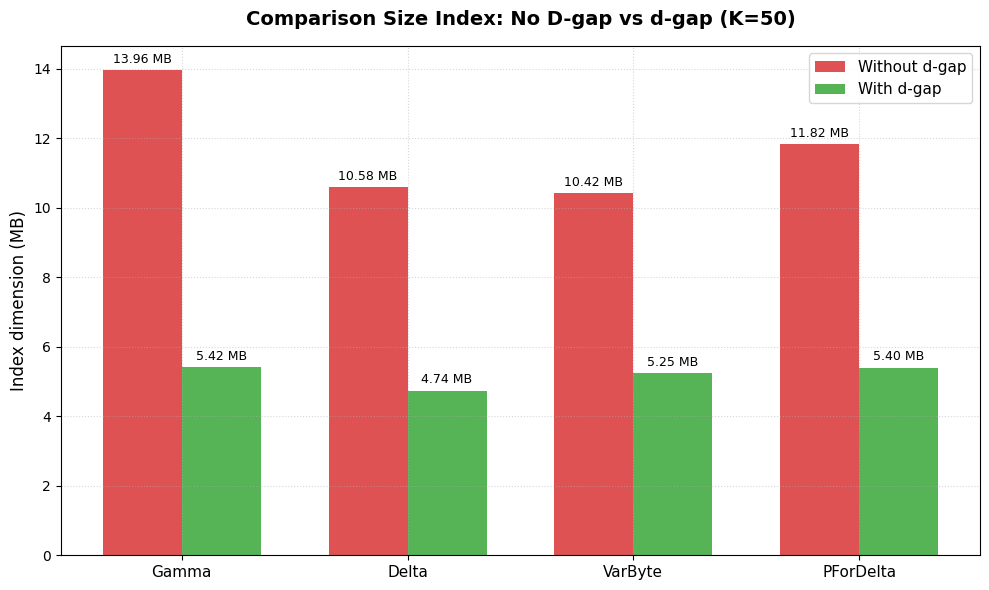

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

MB_FACTOR = 1024 ** 2
algorithms = ['Gamma', 'Delta', 'VarByte', 'PForDelta']

size_no_dgap = [
    results_no_d_gap_gamma[0]["total_bytes"] / MB_FACTOR,
    results_no_d_gap_delta[0]["total_bytes"] / MB_FACTOR,
    results_no_d_gap_var_byte[0]["total_bytes"] / MB_FACTOR,
    results_no_d_gap_pfor_delta[0]["total_bytes"] / MB_FACTOR
]

size_dgap = [
    results_d_gap_gamma[0]["total_bytes"] / MB_FACTOR,
    results_d_gap_delta[0]["total_bytes"] / MB_FACTOR,
    results_d_gap_var_byte[0]["total_bytes"] / MB_FACTOR,
    results_d_gap_pfor_delta[0]["total_bytes"] / MB_FACTOR
]

x = np.arange(len(algorithms))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, size_no_dgap, width, label='Without d-gap', color='#d62728', alpha=0.8)
rects2 = ax.bar(x + width/2, size_dgap, width, label='With d-gap', color='#2ca02c', alpha=0.8)

ax.set_title("Comparison Size Index: No D-gap vs d-gap (K=50)", fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Index dimension (MB)', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(algorithms, fontsize=11)
ax.legend(fontsize=11)
ax.grid(True, linestyle=':', alpha=0.5)


def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f} MB',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

## Decompression experiment

In [ ]:
from time import perf_counter
import copy

def decompress_list(src_index, method):
    idx = copy.deepcopy(src_index)
    
    if not src_index.removed_tf : 
        idx.remove_tf()

    idx.compress_index(method)
    start = perf_counter()
    idx.decompress_index(method)
    elapsed_time = perf_counter() - start
    
    return idx.get_approx_size(), elapsed_time

In [ ]:
from time import perf_counter
import copy

# extract the top 100 most frequent terms from the reordered index
top_terms = sorted(
    reordered_index.index.keys(), 
    key=lambda term: len(reordered_index.index[term]), 
    reverse=True
)[:100]

print("Most frequent terms:", top_terms)

# we extract the postings for these top terms to create a new index for testing decompression
top_terms_postings = {term: reordered_index.index[term] for term in top_terms}

decompression_benchmarks = {}


metodi = ["gamma", "delta", "varbyte", "pfor_delta"]


for metodo in metodi:

    test_index = Index()
    test_index.clear_index()
    

    test_index.num_docs = reordered_index.num_docs
    test_index.d_gap_index_ = reordered_index.d_gap_index_
    test_index.removed_tf = reordered_index.removed_tf
    
    
    test_index.index = copy.deepcopy(top_terms_postings)
    
    # compression
    test_index.remove_tf()
    test_index.compress_index(method=metodo)
    
    # decompression
    start_time = perf_counter()
    test_index.decompress_index()
    end_time = perf_counter()

    execution_time = end_time - start_time
    decompression_benchmarks[metodo] = execution_time
    
    print(f"Decompression time for {metodo:<10}: {execution_time:.6f} seconds")



Most frequent terms: ['the', 'of', 'and', 'a', 'to', 'in', 'is', 'for', 'that', 'or', 'on', 'with', 'are', 'as', 'it', 'by', 'you', 'from', 'be', 'an', 'this', 'can', 'your', 'at', '1', 'have', 'not', '2', 'was', 'if', 'one', 'which', 'more', 'has', 'will', 'but', 'when', 'also', 'all', 'other', 'most', '3', 'about', 'may', 'its', 'they', 'than', 'there', 'their', 'up', 'first', 'time', 'used', 'some', 'new', 'use', 'into', 'how', 'what', 'i', 'who', 'two', 'these', 'so', 'out', 'only', 'after', 'do', 'many', 'any', '4', 'people', 'years', 'we', 'like', 'get', 'over', 'such', 'been', 'between', 'his', 'no', 'make', 'us', 'he', 'just', 'see', 'our', 'were', 'then', 'each', '5', 'number', 'year', 'states', 'through', 'need', 'during', 'called', 'because']
Decompression time for gamma     : 1.979747 seconds
Decompression time for delta     : 3.683503 seconds
Decompression time for varbyte   : 1.709005 seconds
Handling PForDelta with is_decompressing=False
Handling PForDelta with is_decomp

C:\Users\Utente\AppData\Local\Temp\ipykernel_7156\900187172.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels([alg.upper() for alg in algoritmi])


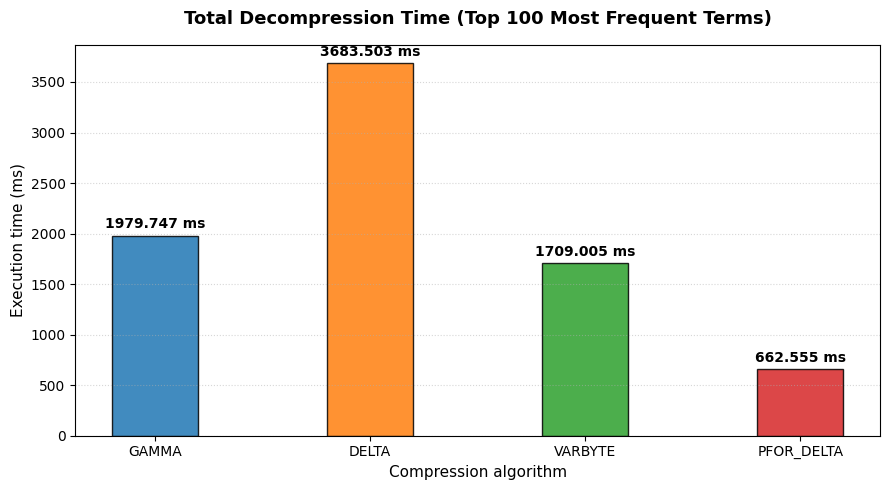

In [ ]:
import matplotlib.pyplot as plt

algoritmi = list(decompression_benchmarks.keys())
tempi = list(decompression_benchmarks.values())


tempi_ms = [t * 1000 for t in tempi]

plt.figure(figsize=(9, 5))

colors = {
    'gamma': '#1f77b4', 
    'delta': '#ff7f0e', 
    'varbyte': '#2ca02c', 
    'pfor_delta': '#d62728'
}
bar_colors = [colors.get(alg, '#7f7f7f') for alg in algoritmi]

bars = plt.bar(algoritmi, tempi_ms, color=bar_colors, alpha=0.85, edgecolor='black', width=0.4)

plt.title("Total Decompression Time (Top 100 Most Frequent Terms)", fontsize=13, fontweight='bold', pad=15)
plt.ylabel("Execution time (ms)", fontsize=11)
plt.xlabel("Compression algorithm", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.5, axis='y')


plt.gca().set_xticklabels([alg.upper() for alg in algoritmi])

for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.3f} ms',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # 3 punti di scostamento verticale
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()

plt.show()